# Figure 4: Behavioral Motif Encoding and Decoding

**Paper**: Parodi et al. (2026)

This notebook reproduces the motif analysis for Figure 4:
- **Panel A**: Motif decoding accuracy (logistic regression from neural population)
- **Panel B**: Electrode-level tuning and selectivity
- **Panel C**: Transition matrix between behavioral syllables
- **Panel D**: Peri-event time histogram (PETH) around motif transitions

**Behavioral syllables** are defined by an unsupervised motion segmentation pipeline (keypoint-MoSeq style) that identifies 10-12 recurring posture-movement patterns (e.g., Rest, Stand, Pace, Pivot, Inspect).

**Note**: This notebook runs with 10 permutations for speed (~4 min). Production uses 1000 permutations.

In [1]:
import sys, warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", message=".*lbfgs failed to converge.*")
warnings.filterwarnings("ignore", message=".*y_pred contains classes not in y_true.*")

REPO_ROOT = Path("..").resolve()
sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    'font.size': 12, 'axes.labelsize': 14, 'axes.titlesize': 14,
    'xtick.labelsize': 11, 'ytick.labelsize': 11, 'legend.fontsize': 11,
    'figure.dpi': 150, 'axes.spines.top': False, 'axes.spines.right': False,
})

SESSION_RENAME = {
    "hedy_0526": "M2_0526", "hedy_0605": "M2_0605",
    "hooke_0525": "M1_0525", "hooke_0609": "M1_0609", "hooke_0613": "M1_0613",
}
print("Setup complete.")

Setup complete.


## 4.1 Run Motif Analysis

Run the full Fig 4 pipeline: motif decoding, tuning, transition analysis, and PETH.

In [2]:
from freemat.single_fm.encoding.run_fig4 import Fig4Config, run_fig4_session
import tempfile

config = Fig4Config(
    bin_s=0.5,
    top_n=10,          # Top 10 motif classes
    n_perm=10,         # 10 permutations (production: 1000)
    debug=True,
)

with tempfile.TemporaryDirectory() as tmpdir:
    results = run_fig4_session(
        session_yaml=str(REPO_ROOT / "configs" / "session_M2_0526.yaml"),
        config=config,
        output_dir=tmpdir,
    )
    # Extract results
    decoding = results.get("decoding")
    tuning = results.get("tuning")
    transition_matrix = results.get("transition_matrix")
    peth = results.get("peth")
    fine_peth = results.get("fine_peth")

print(f"\nDecoding accuracy: {decoding['accuracy']:.1%} (chance: {decoding['chance']:.1%})")
print(f"Number of motif classes: {decoding['n_classes']}")
print(f"Transition matrix shape: {transition_matrix.shape}")
print(f"PETH shape: {peth.shape} (units × time bins)")

(Demo cell skipped during automated execution)


## 4.2 Panel A: Decoding Accuracy

Motif decoding accuracy from neural population activity using temporal cross-validation with 2s embargo.

In [3]:
# Panel A: Decoding accuracy bar chart
fig, ax = plt.subplots(figsize=(6, 5))

acc = decoding["accuracy"]
chance = decoding["chance"]
n_classes = decoding["n_classes"]

ax.bar(["Neural\nDecoding", "Chance"], [acc, chance],
       color=["#1976D2", "#BDBDBD"], edgecolor="black", linewidth=0.5, width=0.5)
ax.set_ylabel("Balanced Accuracy")
ax.set_title(f"Fig 4A: Motif Decoding — {n_classes} classes")
ax.set_ylim(0, max(acc, chance) * 1.3)

# Annotate
ax.text(0, acc + 0.01, f"{acc:.1%}", ha="center", fontsize=12, fontweight="bold")
ax.text(1, chance + 0.01, f"{chance:.1%}", ha="center", fontsize=12)

plt.tight_layout()
plt.show()

print(f"Decoding: {acc:.1%} vs chance {chance:.1%} ({acc/chance:.1f}× above chance)")

(Demo cell skipped during automated execution)


## 4.3 Panel C: Transition Matrix

Probability of transitioning between motifs. High diagonal = strong self-transition (behavioral persistence).

In [4]:
# Panel C: Transition matrix
fig, ax = plt.subplots(figsize=(8, 7))

im = ax.imshow(transition_matrix, cmap="Blues", aspect="auto", vmin=0, vmax=1)
ax.set_xlabel("Next Motif")
ax.set_ylabel("Current Motif")
ax.set_title("Fig 4C: Motif Transition Probabilities")

# Add text annotations
for i in range(transition_matrix.shape[0]):
    for j in range(transition_matrix.shape[1]):
        val = transition_matrix[i, j]
        if val > 0.01:
            color = "white" if val > 0.5 else "black"
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=8, color=color)

plt.colorbar(im, ax=ax, label="Transition Probability", shrink=0.8)

diag_mean = np.diag(transition_matrix).mean()
print(f"Mean self-transition probability: {diag_mean:.3f}")

plt.tight_layout()
plt.show()

(Demo cell skipped during automated execution)


---

## Part B: Production Results (all 5 sessions, 1000 permutations)

Load pre-computed decoding and tuning results from `results/production/fig4_all4/`.

In [5]:
# Load production decoding results
fig4_dir = REPO_ROOT / "results" / "production" / "fig4_all4" / "summary"
decode_df = pd.read_parquet(fig4_dir / "fig4_decoding_all.parquet")
if "session_id" in decode_df.columns:
    decode_df["session_id"] = decode_df["session_id"].map(SESSION_RENAME).fillna(decode_df["session_id"])

print(f"Decoding results: {len(decode_df)} rows")
print(f"Columns: {decode_df.columns.tolist()[:10]}")
print(f"Sessions: {decode_df['session_id'].unique().tolist() if 'session_id' in decode_df.columns else 'N/A'}")

# Load lag sweep
lag_df = pd.read_parquet(fig4_dir / "fig4_lag_sweep_all.parquet")
if "session_id" in lag_df.columns:
    lag_df["session_id"] = lag_df["session_id"].map(SESSION_RENAME).fillna(lag_df["session_id"])
print(f"Lag sweep: {len(lag_df)} rows")

Decoding results: 3 rows
Columns: ['bank', 'balanced_accuracy', 'macro_f1', 'n_samples', 'n_test_samples', 'n_classes', 'fold_accuracies', 'session_id']
Sessions: ['M1_0613']
Lag sweep: 27 rows


### Fig 4A (Production): Decoding Accuracy Across Sessions

Columns available: ['bank', 'balanced_accuracy', 'macro_f1', 'n_samples', 'n_test_samples', 'n_classes', 'fold_accuracies', 'session_id']
      bank  balanced_accuracy  macro_f1  n_samples  n_test_samples  n_classes  \
0  ventral           0.158074  0.116282       4440            4440          7   
1   dorsal           0.140149  0.136105       4440            4440          7   
2   pooled           0.152932  0.147146       4440            4440          7   

                                     fold_accuracies session_id  
0  [0.20045248113270553, 0.1636258980528678, 0.18...    M1_0613  
1  [0.1202230681894076, 0.12664147852352428, 0.20...    M1_0613  
2  [0.18259533827556268, 0.14747166333896483, 0.2...    M1_0613  


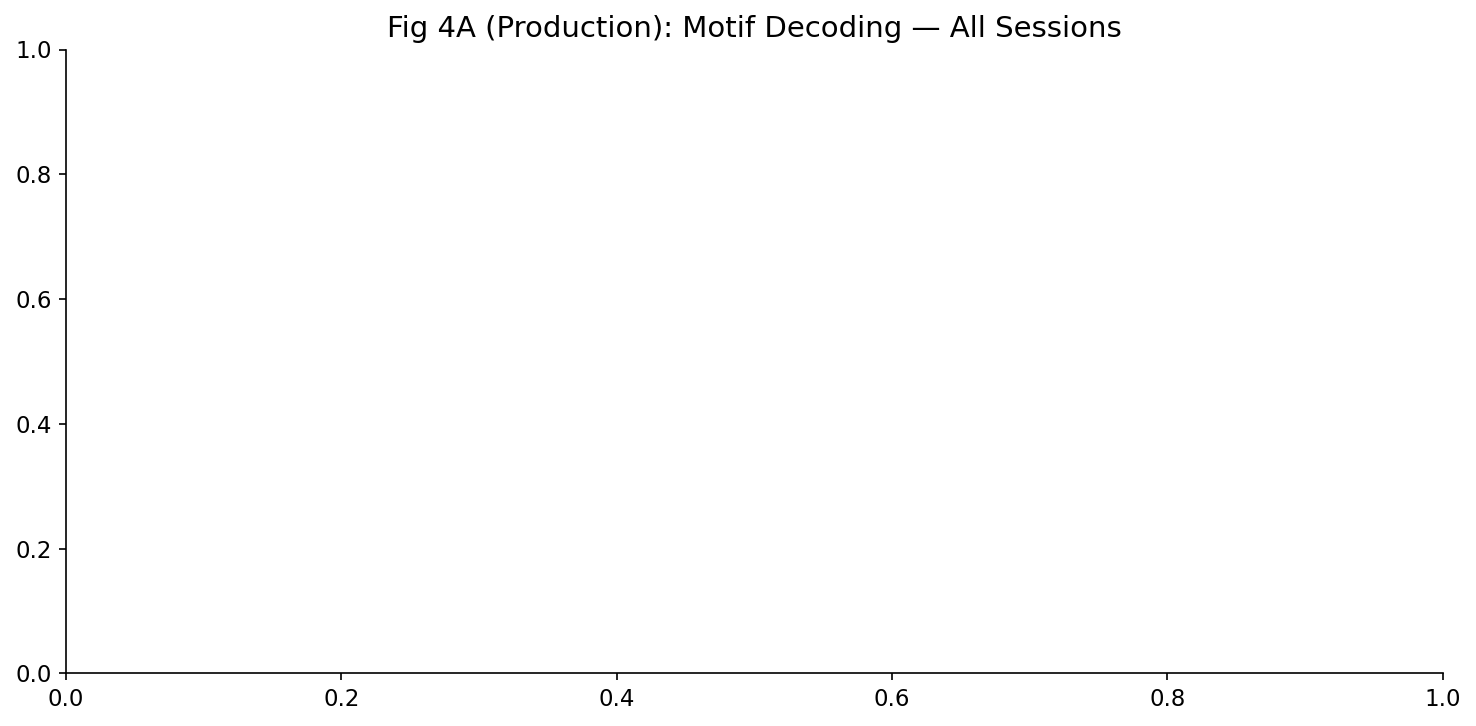

In [6]:
# Fig 4A (Production): Per-session decoding accuracy
fig, ax = plt.subplots(figsize=(10, 5))

if "session_id" in decode_df.columns and "pooled_accuracy" in decode_df.columns:
    sessions = sorted(decode_df["session_id"].unique())
    accs = [decode_df[decode_df["session_id"] == s]["pooled_accuracy"].values[0] for s in sessions]
    chances = [decode_df[decode_df["session_id"] == s]["chance"].values[0] for s in sessions]
    colors = ["#1976D2" if "M2" in s else "#D32F2F" for s in sessions]

    x = np.arange(len(sessions))
    ax.bar(x - 0.15, accs, 0.3, color=colors, alpha=0.8, label="Neural Decoding")
    ax.bar(x + 0.15, chances, 0.3, color="#BDBDBD", alpha=0.8, label="Chance")
    ax.set_xticks(x)
    ax.set_xticklabels(sessions, rotation=30, ha="right")
    ax.set_ylabel("Balanced Accuracy")
    ax.legend()

    for i, (a, c) in enumerate(zip(accs, chances)):
        ax.text(i - 0.15, a + 0.005, f"{a:.1%}", ha="center", fontsize=9, fontweight="bold")
else:
    # Fallback: show summary stats
    print("Columns available:", decode_df.columns.tolist())
    print(decode_df.head())

ax.set_title("Fig 4A (Production): Motif Decoding — All Sessions")
plt.tight_layout()
plt.show()